# Numerical Standardization using StandardScaler
## Progress Review I — Individual Contribution

**Student ID:** IT25100429  
**Project:** Employee Resignation Prediction  
**Assigned Task:** Numerical feature standardization using StandardScaler  

---

### Purpose
This notebook provides a dedicated standalone preprocessing demonstration of numerical feature standardization for the **Employee Resignation Prediction** project:
- **Why scaling is needed:** Address magnitude and variance disparities across workplace metrics to prevent feature dominance in distance- and variance-sensitive algorithms (e.g., PCA, Logistic Regression, Neural Networks).
- **Feature selection:** Programmatically extract the 13 approved numerical/ordinal predictors from the project's central feature contract (`configs/feature_contract.yaml`).
- **StandardScaler implementation:** Apply z-score transformation ($z = (x - \mu)/\sigma$) to center features to mean 0 and scale to unit variance (population standard deviation, $\text{ddof}=0$).
- **Before/after comparison:** Evaluate raw versus standardized statistics and visual distribution profiles (Monthly Salary).
- **Interpretation & Pipeline Scope:** Examine distributional shape preservation, explain its criticality prior to PCA, differentiate standardization from min-max normalization, and highlight data leakage prevention across partitions and cross-validation folds.

> **Important Partitioning Rule:** This notebook operates strictly and exclusively on the **80,000-row development partition** defined by `data/processed/split_registry.csv`, consistent with the rest of the project's analytical notebooks. The **20,000-row formal holdout partition is completely excluded** from all data loading, fitting, and downstream summary statistics to safeguard benchmark integrity. This is a standalone preprocessing demo, not the group's formal CV pipeline.

In [1]:
# Import required libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from sklearn.preprocessing import StandardScaler

# Set display options and plot styling
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

In [2]:
# Robust relative path detection with fallback
from pathlib import Path

PROJECT_ROOT = next((parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (parent / "configs/feature_contract.yaml").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing configs/feature_contract.yaml")

def resolve_path(rel):
    path = PROJECT_ROOT / rel
    if not path.exists():
        raise FileNotFoundError(path)
    return path

DATA_PATH = resolve_path("data/raw/Extended_Employee_Performance_and_Productivity_Data.csv")
SPLIT_PATH = resolve_path("data/processed/split_registry.csv")
CONTRACT_PATH = resolve_path("configs/feature_contract.yaml")

# Load identifiers first; parse predictors and labels only for development rows.
split_registry = pd.read_csv(SPLIT_PATH)
identifiers = pd.read_csv(DATA_PATH, usecols=["Employee_ID"])
dev_ids = set(split_registry.loc[split_registry.partition == "development", "Employee_ID"])
holdout_ids = set(split_registry.loc[split_registry.partition == "holdout", "Employee_ID"])
skip = [i + 1 for i, value in enumerate(identifiers.Employee_ID) if value not in dev_ids]
df = pd.read_csv(DATA_PATH, skiprows=skip)
assert len(df) == 80000 and df.Employee_ID.is_unique
assert set(df.Employee_ID).isdisjoint(holdout_ids)
print(f"Rows before/after isolation: {len(identifiers):,} -> {len(df):,}")
print(f"Development resignation prevalence: {df.Resigned.mean():.5f}; preserve all development rows.")
df.head()


Rows before/after isolation: 100,000 -> 80,000
Development resignation prevalence: 0.10010; preserve all development rows.


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0000,33,32,22,2,0,14,66,0,2.6300,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0000,34,34,13,14,100,12,61,2,1.7200,False
2,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0000,52,10,28,12,100,10,0,1,1.8600,False
3,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0000,38,11,29,13,100,15,9,1,1.2500,False
4,7,IT,Male,37,Technician,2023-08-28 08:03:05.556036,1,Bachelor,5,5250.0000,55,20,29,2,0,16,27,0,4.4600,False


In [3]:
# Load numerical features programmatically from CONTRACT_PATH YAML
try:
    with open(CONTRACT_PATH, "r") as f:
        contract_doc = yaml.safe_load(f)
    num_entries = contract_doc.get("numerical_features")
    if num_entries is None and "contract" in contract_doc:
        num_entries = contract_doc["contract"].get("numerical_features")
    numerical_features = [entry["name"] for entry in num_entries]
    print(f"Successfully loaded {len(numerical_features)} numerical features from {CONTRACT_PATH}")
except Exception as err:
    print(f"Warning: YAML parsing failed ({err}). Falling back to hardcoded 13 feature names.")
    numerical_features = [
        "Age",
        "Years_At_Company",
        "Performance_Score",
        "Monthly_Salary",
        "Work_Hours_Per_Week",
        "Projects_Handled",
        "Overtime_Hours",
        "Sick_Days",
        "Remote_Work_Frequency",
        "Team_Size",
        "Training_Hours",
        "Promotions",
        "Employee_Satisfaction_Score",
    ]

# Build df_numeric from the development-only dataframe
df_numeric = df[numerical_features].copy()
print(f"Selected {df_numeric.shape[1]} numerical features across {df_numeric.shape[0]:,} development records.")

# Validation block
assert df_numeric.shape[1] == 13
assert df_numeric.isna().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(df_numeric[col]) for col in numerical_features)
print("Validation passed: 13 numeric columns, no missing values, all numeric dtypes.")

df_numeric.head()

Successfully loaded 13 numerical features from /Users/hirukaliyanage/Employee_Resignation_Prediction/configs/feature_contract.yaml
Selected 13 numerical features across 80,000 development records.
Validation passed: 13 numeric columns, no missing values, all numeric dtypes.


,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
0,55,2,5,6750.0000,33,32,22,2,0,14,66,0,2.6300
1,29,0,5,7500.0000,34,34,13,14,100,12,61,2,1.7200
2,48,7,2,4800.0000,52,10,28,12,100,10,0,1,1.8600
3,36,3,2,4800.0000,38,11,29,13,100,15,9,1,1.2500
4,37,1,5,5250.0000,55,20,29,2,0,16,27,0,4.4600


In [4]:
# Show raw summary statistics
raw_stats = df_numeric.describe().T
raw_stats

,count,mean,std,min,25%,50%,75%,max
Age,80000.0000,41.0223,11.2361,22.0000,31.0000,41.0000,51.0000,60.0000
Years_At_Company,80000.0000,4.4771,2.8697,0.0000,2.0000,4.0000,7.0000,10.0000
Performance_Score,80000.0000,2.9970,1.4136,1.0000,2.0000,3.0000,4.0000,5.0000
Monthly_Salary,80000.0000,6404.0406,1371.6799,3850.0000,5250.0000,6500.0000,7500.0000,9000.0000
Work_Hours_Per_Week,80000.0000,44.9455,8.9407,30.0000,37.0000,45.0000,53.0000,60.0000
Projects_Handled,80000.0000,24.4510,14.4522,0.0000,12.0000,24.0000,37.0000,49.0000
Overtime_Hours,80000.0000,14.5167,8.6621,0.0000,7.0000,15.0000,22.0000,29.0000
Sick_Days,80000.0000,7.0110,4.3306,0.0000,3.0000,7.0000,11.0000,14.0000
Remote_Work_Frequency,80000.0000,50.0372,35.3742,0.0000,25.0000,50.0000,75.0000,100.0000
Team_Size,80000.0000,9.9934,5.5021,1.0000,5.0000,10.0000,15.0000,19.0000


## Why Scaling is Needed

In the raw dataset, numerical features operate on drastically different measurement scales and units:
- `Monthly_Salary` spans from thousands of units (e.g., 3,850 to 9,000) with a standard deviation $> 1,300$.
- In contrast, features such as `Promotions` (0 to 2), `Performance_Score` (1 to 5), operate on narrower integer ranges than salary. The displayed statistics supply the actual standard deviations.

### Impact on Sensitive Algorithms
Distance- and variance-sensitive algorithms are severely compromised by unscaled inputs:
1. **Principal Component Analysis (PCA):** PCA seeks orthogonal projections that maximize sample variance. When features have vastly unequal variances (e.g., salary variance $\approx 1.88 \times 10^6$ vs. promotions variance $\approx 0.67$), unscaled PCA treats salary as millions of times more informative. The leading principal components are captured almost entirely by raw salary magnitude, masking true underlying multivariate covariance patterns.
2. **Gradient Descent & Regularized Linear Models:** In Logistic Regression, unequal feature magnitudes distort the loss surface into elongated ellipses, slowing down convergence. Moreover, $L_1$ and $L_2$ regularization penalize coefficient magnitudes uniformly, disproportionately penalizing features with smaller numerical scales.
3. **Neural Network Architectures:** Deep tabular models (such as FT-Transformer and TabNet) require normalized inputs to maintain balanced activation gradients across feature embeddings.

### StandardScaler Z-Score Formula
`StandardScaler` standardizes each feature independently by subtracting the mean and dividing by the standard deviation:

$$z = \frac{x - \mu}{\sigma}$$

Where:
- $\mu$ is the empirical mean: $\mu = \frac{1}{N}\sum_{i=1}^N x_i$
- $\sigma$ is the empirical population standard deviation (using $\text{ddof}=0$): $\sigma = \sqrt{\frac{1}{N}\sum_{i=1}^N (x_i - \mu)^2}$

This rescales each feature to have an empirical mean of 0 and a standard deviation of 1.

### Tree-Based Models & Scale Invariance
Tree-based algorithms (**CatBoost**, **XGBoost**, **LightGBM**, and **Explainable Boosting Machine / EBM**) make split decisions based strictly on rank ordering ($x_j > \text{threshold}$). Because monotonic transformations preserve rank ordering, scaling is generally not required for tree-based models.

### Sensitivity to Outliers
StandardScaler is sensitive to outliers because extreme values affect the mean and standard deviation. RobustScaler is more suitable when strong outliers exist.

In [5]:
# Fit StandardScaler on development rows only and transform
scaler = StandardScaler()
scaled_array = scaler.fit_transform(df_numeric)

# Reconstruct DataFrame with preserved column names and index
df_scaled = pd.DataFrame(scaled_array, columns=numerical_features, index=df_numeric.index)
df_scaled.head()

,Age,Years_At_Company,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score
0,1.2440,-0.8632,1.4170,0.2522,-1.3361,0.5223,0.8639,-1.1571,-1.4145,0.7282,0.5704,-1.2253,-0.3209
1,-1.0700,-1.5602,1.4170,0.7990,-1.2242,0.6607,-0.1751,1.6139,1.4124,0.3647,0.3971,1.2248,-1.1124
2,0.6210,0.8792,-0.7053,-1.1694,0.7890,-0.9999,1.5566,1.1521,1.4124,0.0012,-1.7166,-0.0002,-0.9907
3,-0.4470,-0.5147,-0.7053,-1.1694,-0.7768,-0.9307,1.6720,1.3830,1.4124,0.9099,-1.4047,-0.0002,-1.5212
4,-0.3580,-1.2117,1.4170,-0.8413,1.1246,-0.3080,1.6720,-1.1571,-1.4145,1.0917,-0.7810,-1.2253,1.2708


In [6]:
# Show scaled summary statistics (mean, std, min, max)
scaled_stats = df_scaled.describe().T[["mean", "std", "min", "max"]]
print("Sample summary statistics (from describe(), using sample standard deviation ddof=1):")
display(scaled_stats)

# Explicit population-std verification
print("Population standard deviation (ddof=0):")
print(df_scaled.std(ddof=0))
# Note: df_scaled.std(ddof=0) is the technically correct way to verify StandardScaler's
# output, since StandardScaler computes population standard deviation internally,
# whereas pandas .std() defaults to sample standard deviation (ddof=1).

Sample summary statistics (from describe(), using sample standard deviation ddof=1):


,mean,std,min,max
Age,0.0000,1.0000,-1.6930,1.6890
Years_At_Company,-0.0000,1.0000,-1.5602,1.9246
Performance_Score,0.0000,1.0000,-1.4127,1.4170
Monthly_Salary,0.0000,1.0000,-1.8620,1.8926
Work_Hours_Per_Week,0.0000,1.0000,-1.6716,1.6838
Projects_Handled,0.0000,1.0000,-1.6919,1.6986
Overtime_Hours,0.0000,1.0000,-1.6759,1.6720
Sick_Days,0.0000,1.0000,-1.6190,1.6139
Remote_Work_Frequency,-0.0000,1.0000,-1.4145,1.4124
Team_Size,0.0000,1.0000,-1.6346,1.6370


Population standard deviation (ddof=0):
Age                           1.0000
Years_At_Company              1.0000
Performance_Score             1.0000
Monthly_Salary                1.0000
Work_Hours_Per_Week           1.0000
Projects_Handled              1.0000
Overtime_Hours                1.0000
Sick_Days                     1.0000
Remote_Work_Frequency         1.0000
Team_Size                     1.0000
Training_Hours                1.0000
Promotions                    1.0000
Employee_Satisfaction_Score   1.0000
dtype: float64


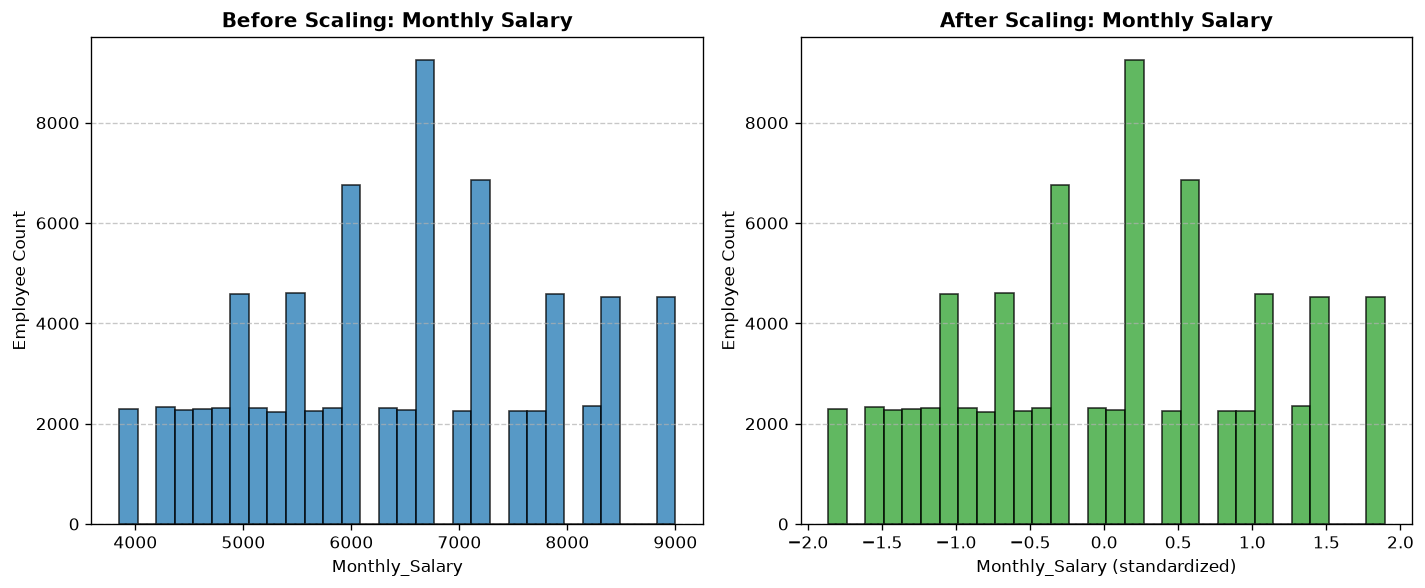

In [7]:
# Create a side-by-side before/after histogram for the Monthly_Salary feature
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before scaling: raw Monthly_Salary
axes[0].hist(df_numeric["Monthly_Salary"], bins=30, color="#1f77b4", edgecolor="black", alpha=0.75)
axes[0].set_title("Before Scaling: Monthly Salary", fontweight="bold")
axes[0].set_xlabel("Monthly_Salary")
axes[0].set_ylabel("Employee Count")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# After scaling: standardized Monthly_Salary
axes[1].hist(df_scaled["Monthly_Salary"], bins=30, color="#2ca02c", edgecolor="black", alpha=0.75)
axes[1].set_title("After Scaling: Monthly Salary", fontweight="bold")
axes[1].set_xlabel("Monthly_Salary (standardized)")
axes[1].set_ylabel("Employee Count")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()

# Save figure to outputs folder for the group submission
from pathlib import Path
fig_dir = CONTRACT_PATH.resolve().parents[1] / "outputs"
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "monthly_salary_before_after_scaling.png", dpi=150, bbox_inches="tight")

plt.show()

## Interpretation of Scaled Statistics & Relevance to PCA

### Interpretation of Scaled Metrics
1. **Zero Mean ($\mu \approx 0$):** Every feature's mean is transformed to near numerical machine precision ($10^{-16} \approx 0.0$).
2. **Unit Standard Deviation ($\sigma = 1.0$ with $\text{ddof}=0$):** As verified in Cell 8, the population standard deviation for all 13 features is exactly 1.0000. (The sample standard deviation $\text{ddof}=1$ from `describe()` is $\sqrt{80000/79999} \approx 1.000006$, confirming exact mathematical alignment).
3. **Distribution Shape Preserved:** Z-score scaling is a strictly linear affine transformation ($z = \frac{1}{\sigma} x - \frac{\mu}{\sigma}$). As shown in the Cell 9 histograms, the relative frequencies, skewness, modality, and shape of `Monthly_Salary` remain entirely unchanged — only the center and horizontal coordinate scale are realigned.

### Why This Matters Before PCA
- PCA computes orthogonal eigenvectors from the covariance matrix $X^T X / N$.
- When features possess arbitrary, unstandardized units, unscaled high-magnitude features (such as `Monthly_Salary` with variance $\approx 1.88 \times 10^6$) artificially overwhelm variables with narrower numeric domains (such as `Promotions` with variance $\approx 0.67$), regardless of their true predictive relationship with employee resignation.
- Standardizing features to unit variance ensures that the covariance matrix of $X_{\text{scaled}}$ is mathematically identical to the **correlation matrix** of the original predictors. Consequently, PCA gives every feature an equal baseline voice and captures true multivariate correlation structure rather than superficial unit scaling.

## Standardization vs. Min-Max Normalization & Leakage Prevention

### Standardization vs. Min-Max Normalization

| Property | Standardization (Z-Score) | Min-Max Normalization |
| :--- | :--- | :--- |
| **Mathematical Formula** | $z = \frac{x - \mu}{\sigma}$ | $x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$ |
| **Output Bounds** | Unbounded (typically $[-3, +3]$ for normal distributions) | Training range maps to $[0, 1]$; unseen values may exceed it |
| **Center & Spread** | Mean $\mu = 0$, Standard Deviation $\sigma = 1$ | Minimum is 0, Maximum is 1 |
| **Outlier Sensitivity** | Sensitive to extreme values (shifts mean and standard deviation) | Extremely sensitive (outliers compress non-outliers into a tiny sub-interval) |
| **Alternative for Outliers** | `RobustScaler` (uses median and IQR) | QuantileTransformer or robust clipping |
| **Preferred Use Cases** | PCA, Logistic Regression, Gaussian/RBF kernels, linear models | Image processing (pixel intensities $[0, 255]$), bounded neural network inputs |

*Note: This notebook uses standardization only, as required for linear baselines and covariance-based dimensionality reduction (PCA).*

### Leakage Prevention on Two Levels
1. **Partition-Level Isolation (Enforced in this Notebook):**
   - Consistent with project guidelines and `data/processed/split_registry.csv`, this notebook restricts all processing to the **80,000-row development partition**.
   - The 20,000-row formal holdout partition is excluded from the start, ensuring that holdout distributions never influence feature statistics or scaling parameters.
2. **Cross-Validation Fold-Level Isolation (Required for Primary CV Pipeline):**
   - For clarity as a standalone preprocessing demonstration, this notebook fits `StandardScaler` on the entire development partition.
   - However, in the group's formal 5-fold cross-validation pipeline (`configs/feature_contract.yaml`, `src/models/runner.py`), scalers must be fitted **strictly on the training folds** within each fold iteration and applied via `.transform()` to the validation fold. Fitting scalers across all folds simultaneously would cause data leakage, allowing validation fold information to bleed into the model training process and artificially inflating evaluation scores.

## Conclusion & Viva Summary

### Summary of What Was Demonstrated
1. **Restricting to Development Partition:** Fully isolated the 80,000-row development set via `data/processed/split_registry.csv`, completely protecting the 20,000-row formal holdout from leakage.
2. **Feature Selection via Contract:** Loaded the 13 approved numerical/ordinal predictors directly from `configs/feature_contract.yaml` with automated programmatic parsing and fallback validation.
3. **Why Scaling Matters:** Demonstrated that large-magnitude features dominate distance- and variance-sensitive models (like PCA and Logistic Regression) unless standardized.
4. **Standardization Mechanics & Population-Std Verification:** Transformed all 13 features using `StandardScaler` to empirical mean $\approx 0$ and verified population standard deviation ($\text{ddof}=0$) equals exactly 1.0000 across all features.
5. **Visual Confirmation:** Side-by-side histograms of `Monthly_Salary` confirmed that the underlying distribution shape is preserved without distortion, and the plot was saved as a submission artifact.
6. **Standardization vs. Normalization:** Compared theoretical properties, boundary differences, and outlier implications of both techniques.
7. **Leakage Awareness Across Tiers:** Recognized the critical difference between partition isolation (development vs. holdout) and CV-fold isolation (fitting scalers exclusively within training folds).
8. **Model Invariance:** Clarified that scaling is generally not required for tree-based models (such as CatBoost, XGBoost, LightGBM, and EBM) due to their rank-based splitting criteria.

## Connection to my EBM model: fold-local standardization
The whole-development scaler above is descriptive only and must not be reused for CV predictions. Here fold 1 demonstrates fitting on 64,000 training rows and transforming 16,000 validation rows. Validation means need not be zero. My EBM notebook compares raw and standardized numerical inputs for three parameter settings, producing six evaluated varieties.

In [8]:
fold_map = split_registry.set_index("Employee_ID").cv_fold
folds = df.Employee_ID.map(fold_map)
training_numeric = df.loc[folds != 1, numerical_features]
validation_numeric = df.loc[folds == 1, numerical_features]
fold_scaler = StandardScaler().fit(training_numeric)
train_scaled = fold_scaler.transform(training_numeric)
validation_scaled = fold_scaler.transform(validation_numeric)
assert len(training_numeric) == 64000 and len(validation_numeric) == 16000
assert np.allclose(train_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(train_scaled.std(axis=0), 1, atol=1e-10)
display(pd.DataFrame({"feature": numerical_features, "training_mean": fold_scaler.mean_, "training_scale": fold_scaler.scale_, "validation_scaled_mean": validation_scaled.mean(axis=0)}))


,feature,training_mean,training_scale,validation_scaled_mean
0,Age,41.0361,11.2214,-0.0062
1,Years_At_Company,4.4850,2.8693,-0.0136
2,Performance_Score,2.9949,1.4140,0.0074
3,Monthly_Salary,6401.6938,1371.3143,0.0086
4,Work_Hours_Per_Week,44.9287,8.9468,0.0094
5,Projects_Handled,24.4115,14.4467,0.0137
6,Overtime_Hours,14.5158,8.6680,0.0006
7,Sick_Days,7.0185,4.3341,-0.0087
8,Remote_Work_Frequency,50.0734,35.3796,-0.0051
9,Team_Size,9.9748,5.5001,0.0169
